# DSCI 552 - Homework 4

Name: Austin Oliver
<br>
Github Username: awoliver335
<br>
USC ID: 1949137702


I use the data cleaning and features from
[HW3](Oliver_Austin_HW3.ipynb) for the classification problems below.
The [extra practice](Oliver_Austin_HW4_Extra_Practice.ipynb) is in a separate notebook.
I use a random seed of 552.

## Setup

The next cell runs my HW3 notebook to load the recordings, train/test split,
and extracted features. I hide its output here since the HW3 answers are already
in that notebook. Run all cells with the repository folder as the working directory.

There are 69 training recordings and 19 test recordings. As noted in HW3,
three pairs of identical files cross the split: cycling 1/15, lying 1/15,
and lying 3/11. I keep the assigned split, but these duplicates could make
the test results look better.

In [18]:
%%capture hw3_output
from pathlib import Path

assert Path('data').is_dir(), 'Run the notebook from the repository folder.'
assert Path('Oliver_Austin_HW3.ipynb').is_file(), 'Keep the HW3 notebook alongside HW4.'
%run ./Oliver_Austin_HW3.ipynb

In [19]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit, logit
from scipy.stats import norm
from scipy.optimize import linprog
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             recall_score, precision_score, f1_score)
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from threadpoolctl import threadpool_limits

# One thread is faster for these small datasets.
blas_limit = threadpool_limits(limits=1)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.precision', 4)

print(f'Loaded HW3: {len(records)} recordings; {len(train_ids)} training, {len(test_ids)} test.')

Loaded HW3: 88 recordings; 69 training, 19 test.


### Splitting the recordings

I split each recording into $l$ parts using `np.array_split`. The parts differ
in length by at most one sample. I then calculate the seven statistics for all
six series in each part. This gives $42l$ features, but still only 88 recordings.
For example, `mean_s1_seg2` is the mean of series 1 in the second part.
I use mean, maximum, and standard deviation for the scatter plots, as in HW3,
and all seven statistics for the models.

In [20]:
def segmented_features(recording, l):
    values = recording[sensor_columns].to_numpy(dtype=float)
    blocks = np.array_split(values, l, axis=0)
    assert max(map(len, blocks)) - min(map(len, blocks)) <= 1
    result = {}
    for segment, block in enumerate(blocks, start=1):
        statistics = [block.min(axis=0), block.max(axis=0), block.mean(axis=0),
                      np.median(block, axis=0), block.std(axis=0, ddof=1),
                      np.quantile(block, .25, axis=0), np.quantile(block, .75, axis=0)]
        for series in range(1, 7):
            for name, values_by_series in zip(stat_names, statistics):
                result[f'{name}_s{series}_seg{segment}'] = values_by_series[series - 1]
    return result

L_VALUES = range(1, 21)
# Precompute each recording's features; fit scaling and selection inside CV.
segment_data = {
    l: pd.DataFrame.from_dict({i: segmented_features(record, l)
                              for i, record in records.items()}, orient='index')
    for l in L_VALUES
}
train_X = {l: frame.loc[train_ids] for l, frame in segment_data.items()}
test_X = {l: frame.loc[test_ids] for l, frame in segment_data.items()}
y_binary = y_train.isin(['bending1', 'bending2']).astype(int).to_numpy()
y_binary_test = y_test.isin(['bending1', 'bending2']).astype(int).to_numpy()
y_multi = y_train.to_numpy()
y_multi_test = y_test.to_numpy()
groups = metadata.loc[train_ids, 'sha256'].to_numpy()
for l, frame in segment_data.items():
    assert frame.shape == (88, 42 * l)
    assert np.isfinite(frame.to_numpy()).all()
np.testing.assert_allclose(segment_data[1].to_numpy(), features.to_numpy())
display(pd.DataFrame({'l': list(L_VALUES), 'training_rows': 69,
                      'features': [42*l for l in L_VALUES]}))

,l,training_rows,features
0,1,69,42
1,2,69,84
2,3,69,126
3,4,69,168
4,5,69,210
5,6,69,252
6,7,69,294
7,8,69,336
8,9,69,378
9,10,69,420


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Scatter plots of the original recordings

I combine `bending1` and `bending2` into class 1 and put all other activities
in class 0. The plots below use the training data and the mean, maximum, and
standard deviation of series 1, 2, and 6. Each point is one recording.

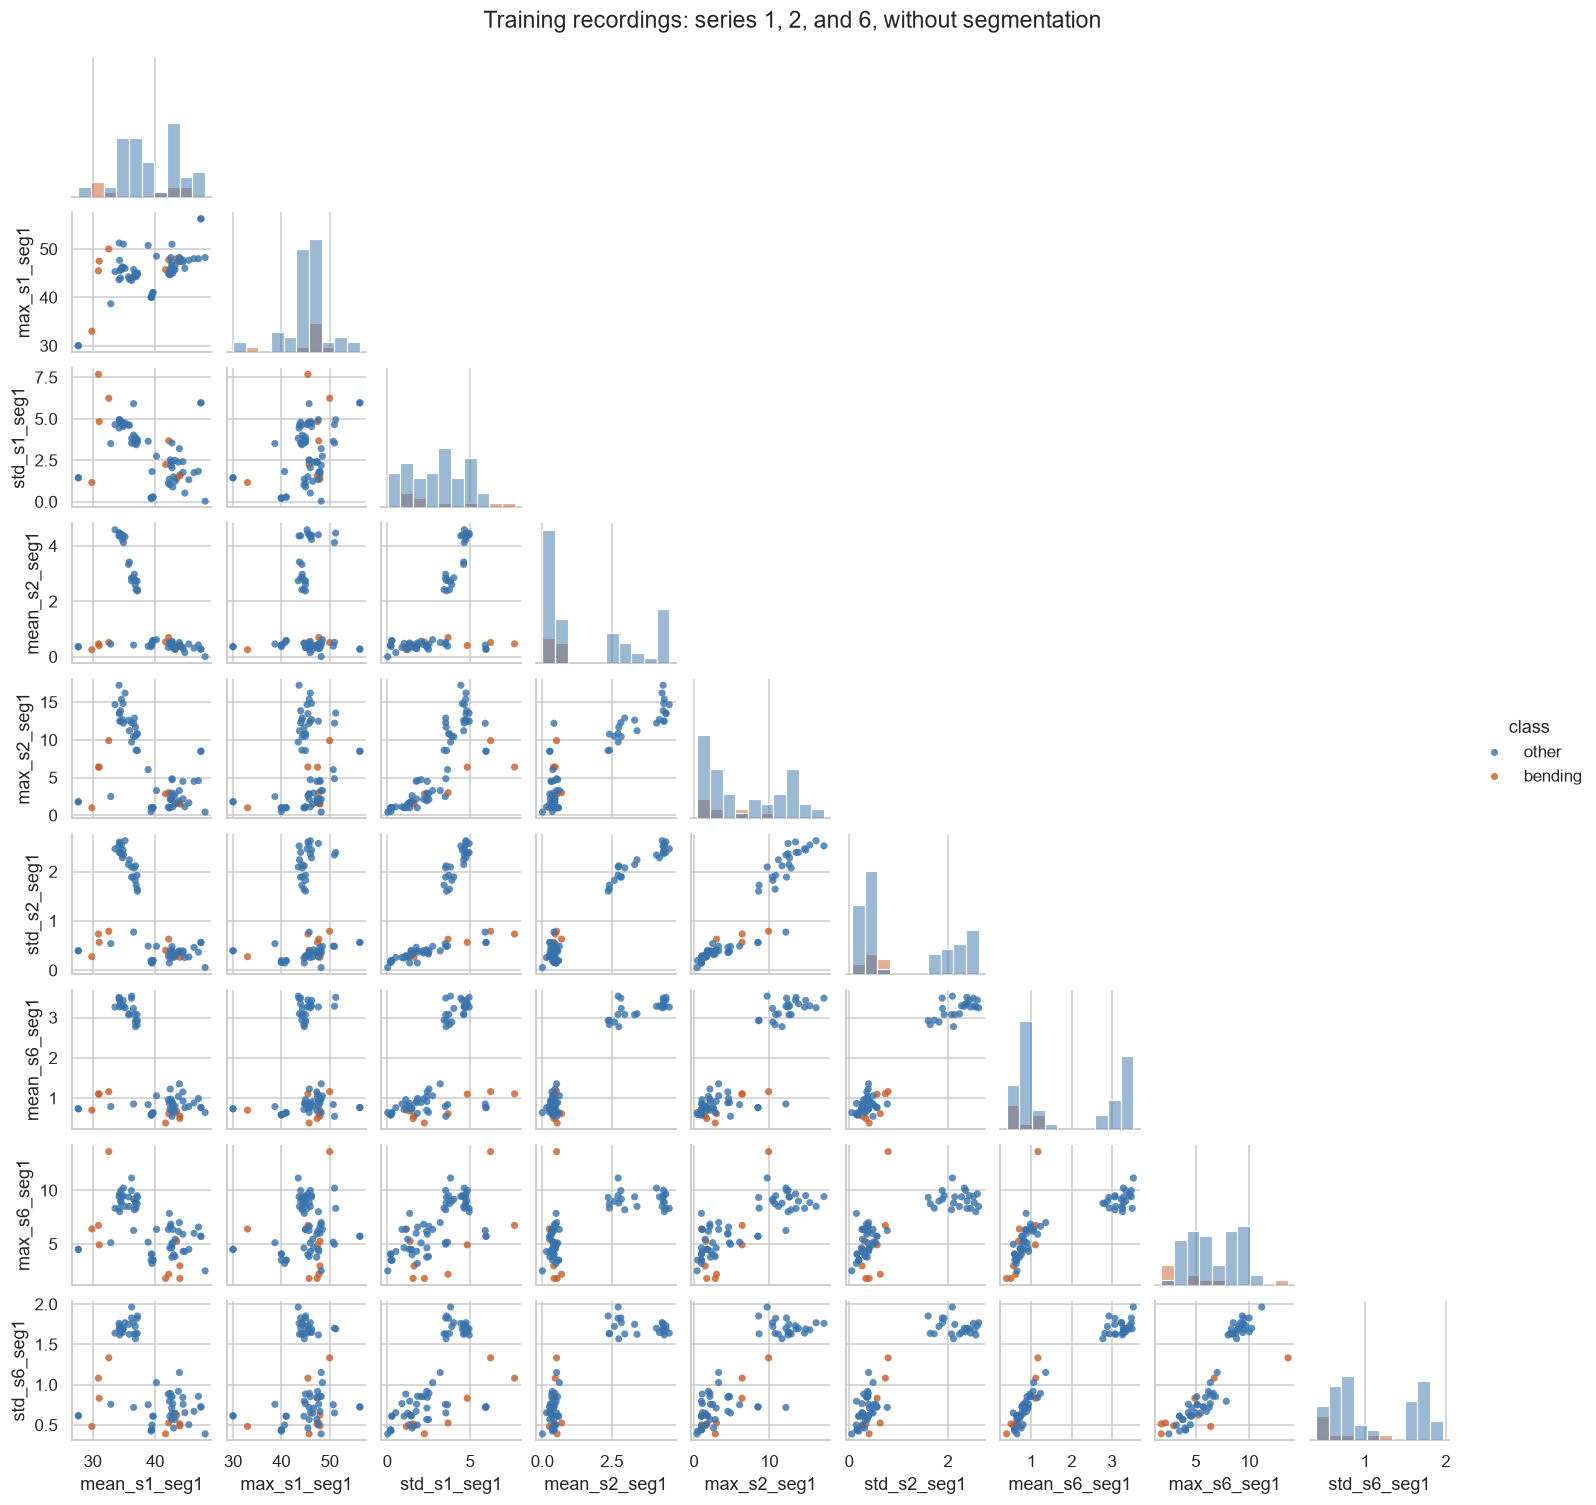

In [21]:
plot_palette = {'other': '#3973ac', 'bending': '#c65e2b'}

def feature_pairplot(l, segments, title):
    columns = [f'{stat}_s{s}_seg{segment}' for segment in segments
               for s in [1, 2, 6] for stat in selected_types]
    frame = train_X[l][columns].copy()
    frame['class'] = np.where(y_binary == 1, 'bending', 'other')
    grid = sns.pairplot(frame, vars=columns, hue='class', hue_order=['other', 'bending'],
                        palette=plot_palette, corner=True, diag_kind='hist',
                        height=1.5, plot_kws={'s': 22, 'alpha': .8, 'linewidth': 0},
                        diag_kws={'bins': 10, 'alpha': .5})
    grid.figure.suptitle(title, y=1.015, fontsize=15)
    plt.show()

feature_pairplot(1, [1], 'Training recordings: series 1, 2, and 6, without segmentation')

#### ii. Scatter plots after splitting each series in two

I first plot the features from each half separately. The third plot compares
features from the first half with those from the second half, so all pairs of
the 18 features are included. There are still 69 training recordings.

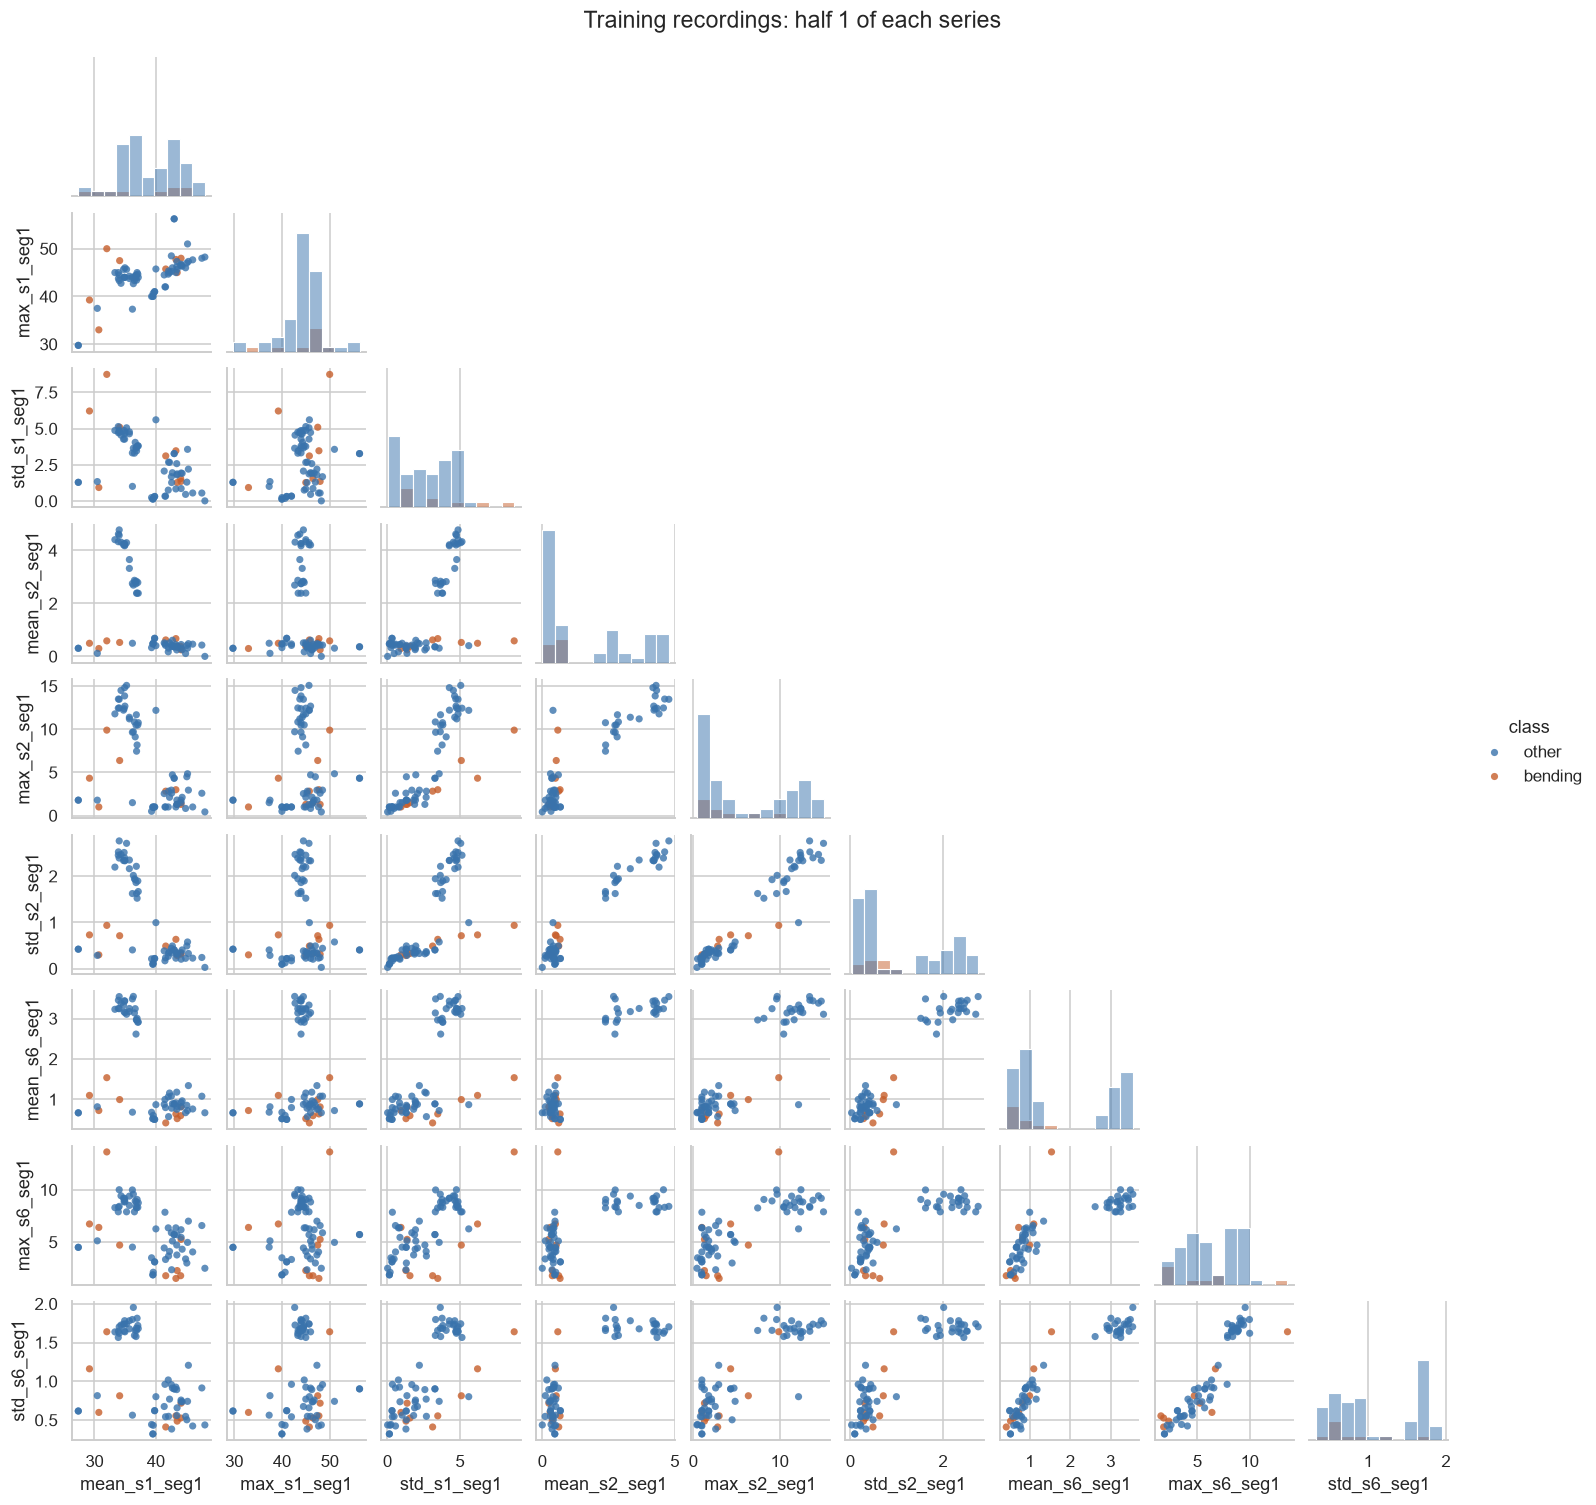

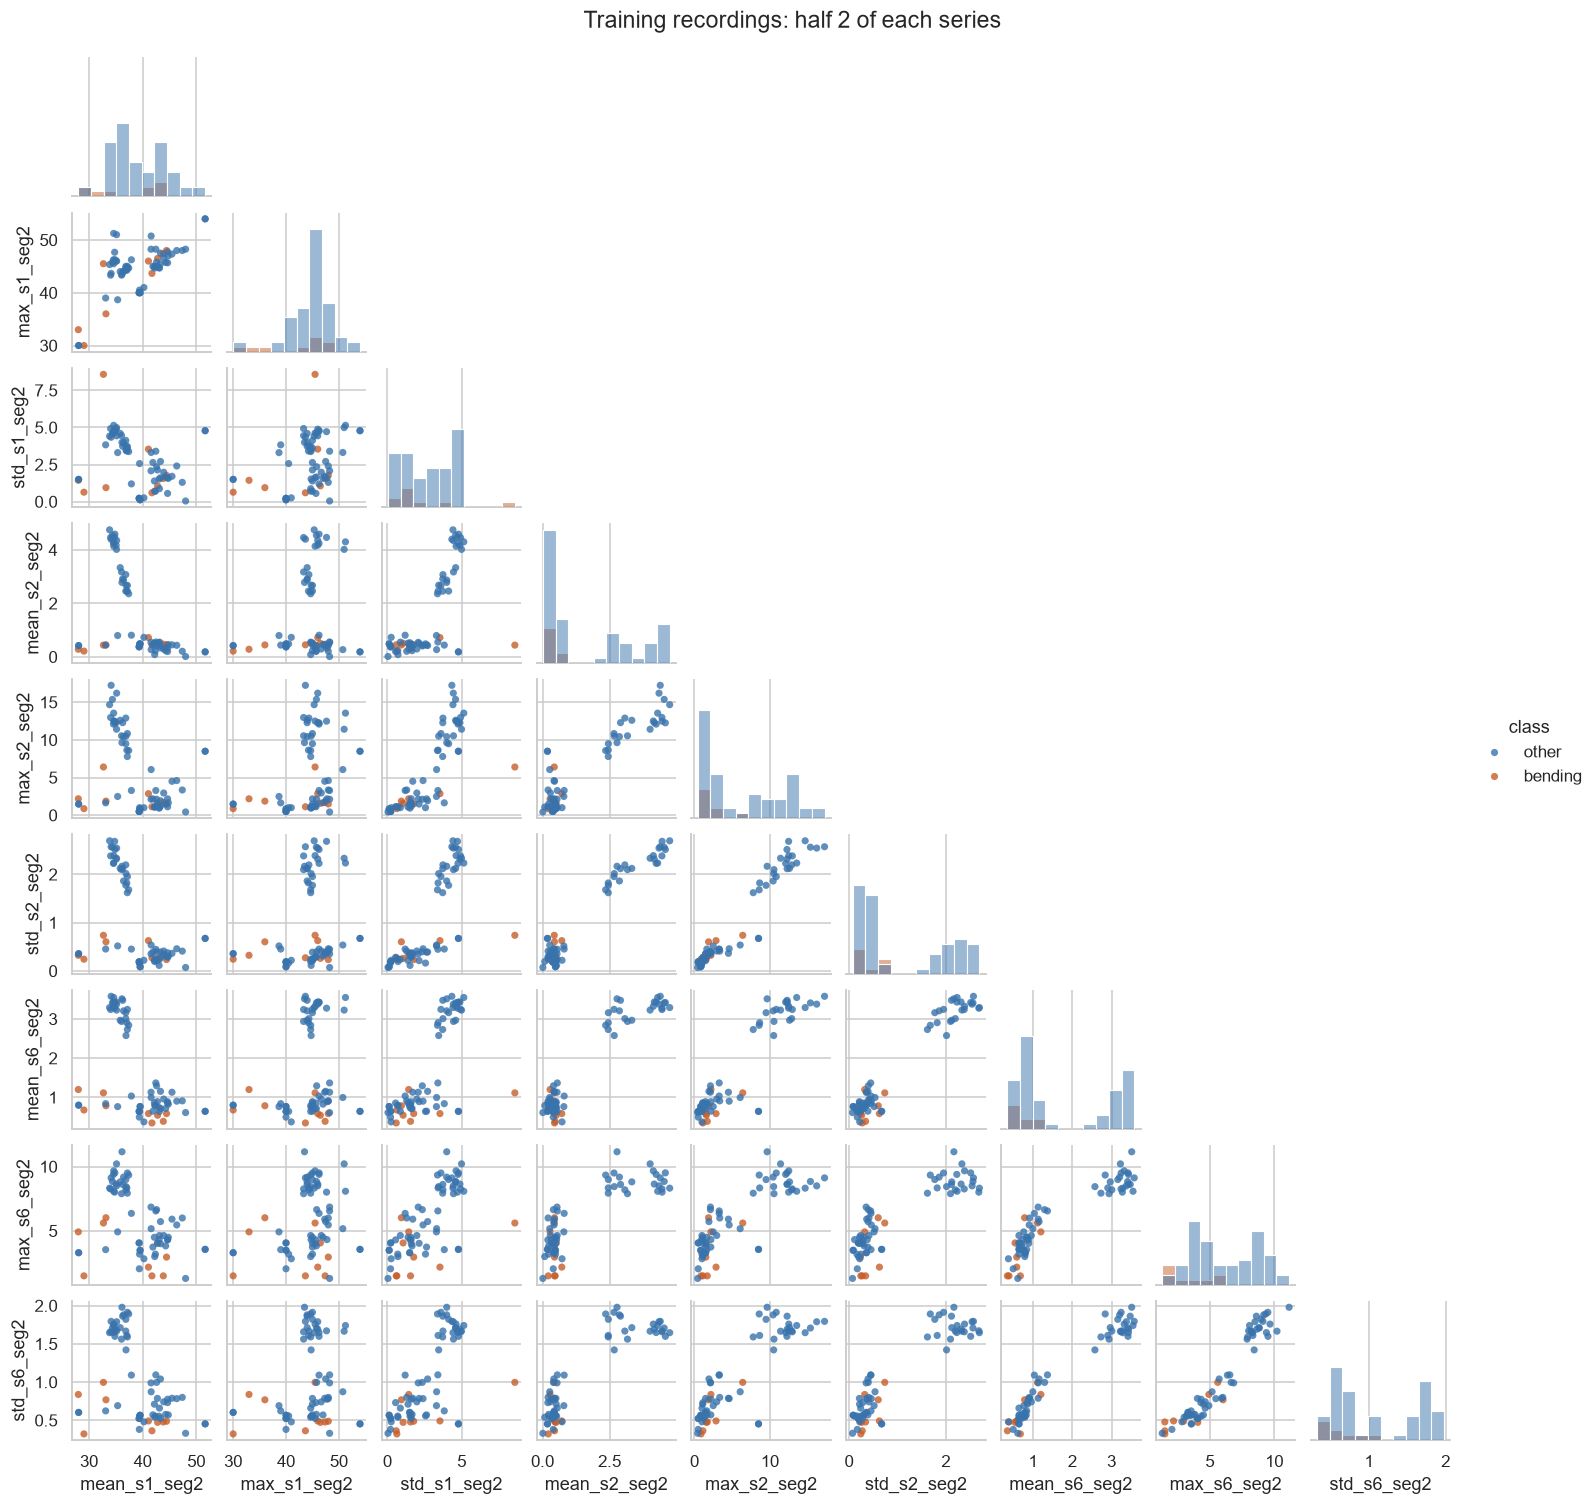

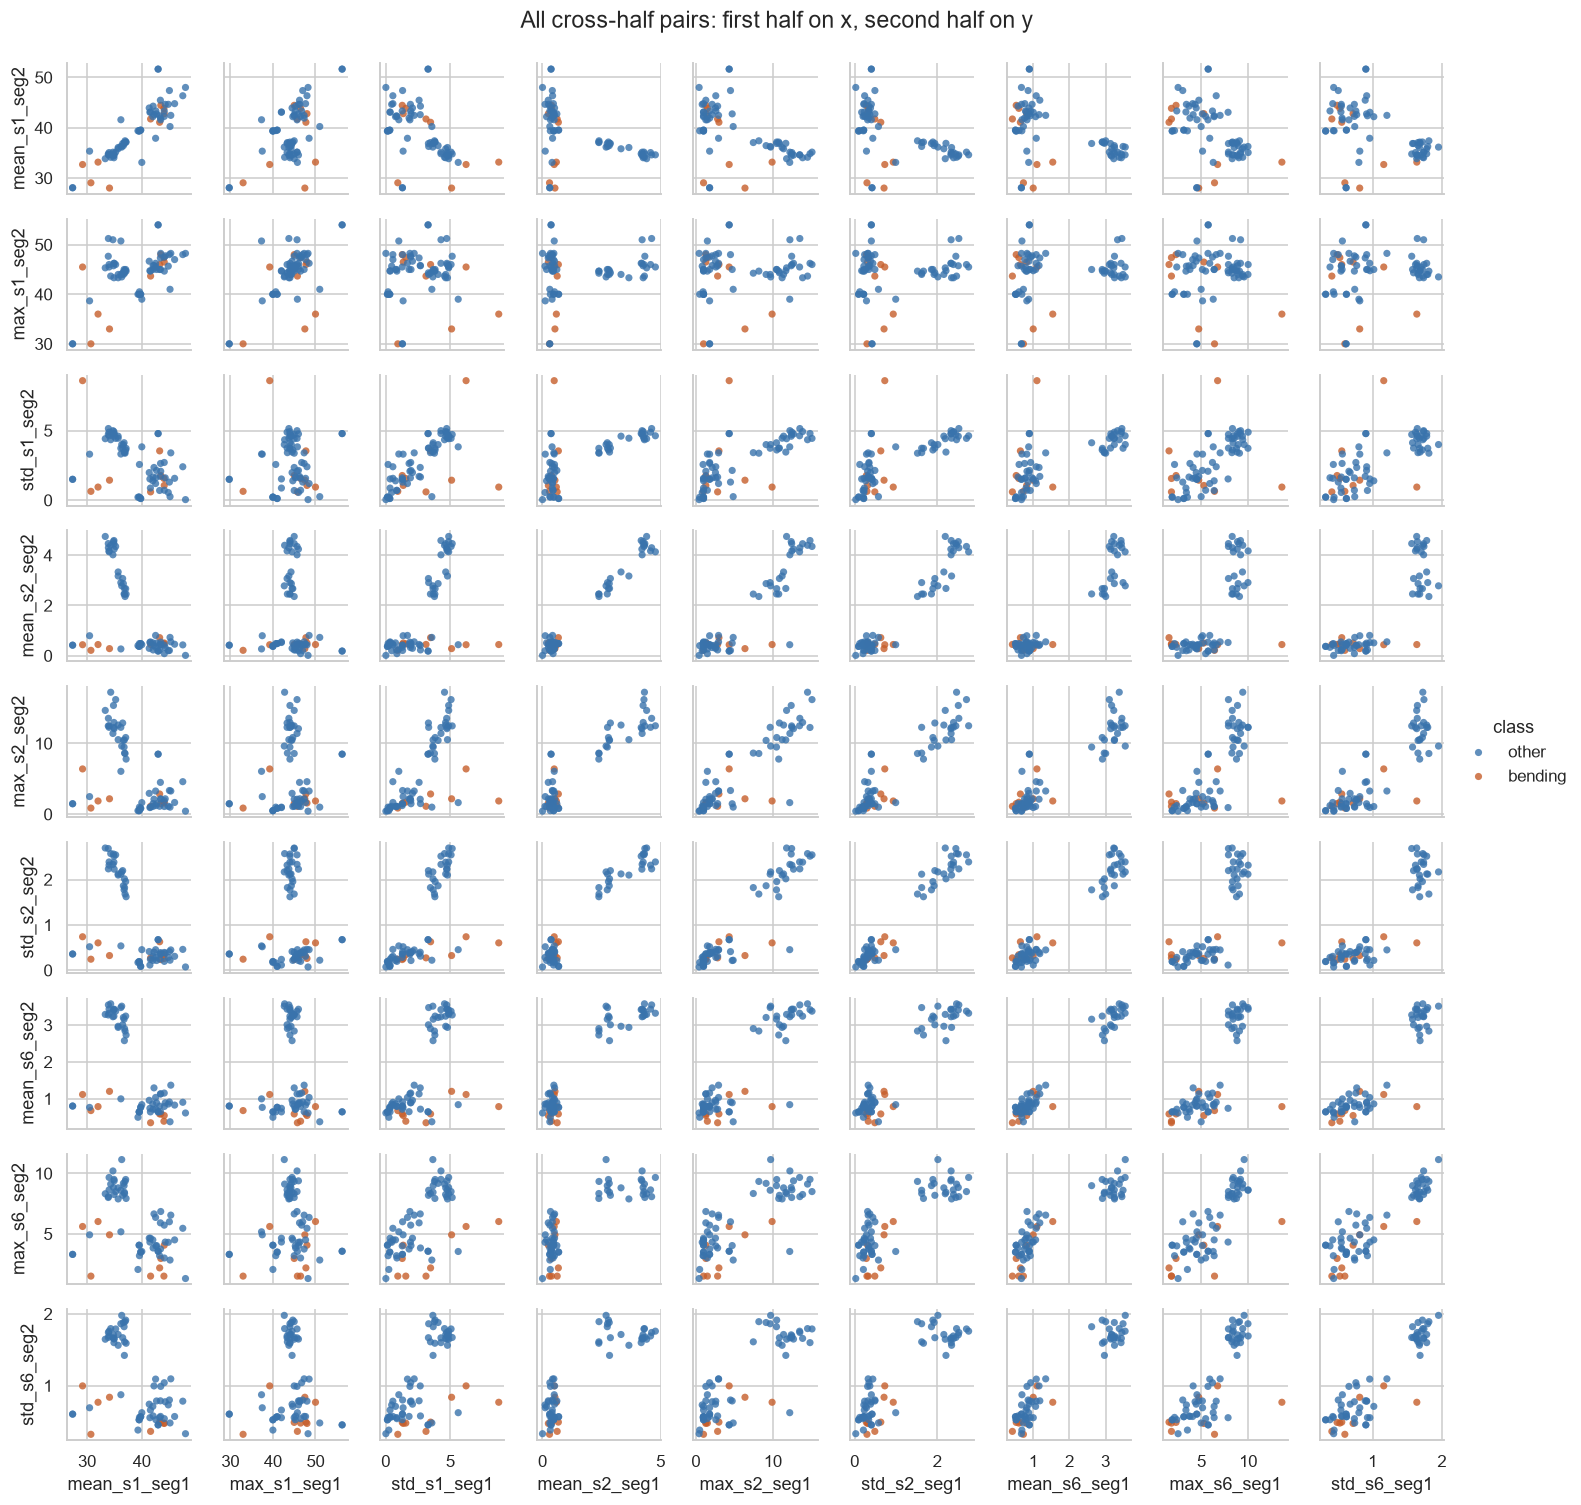

In [22]:
for segment in [1, 2]:
    feature_pairplot(2, [segment], f'Training recordings: half {segment} of each series')

cross_half = train_X[2].copy()
cross_half['class'] = np.where(y_binary == 1, 'bending', 'other')
half1 = [f'{stat}_s{s}_seg1' for s in [1, 2, 6] for stat in selected_types]
half2 = [f'{stat}_s{s}_seg2' for s in [1, 2, 6] for stat in selected_types]
grid = sns.PairGrid(cross_half, x_vars=half1, y_vars=half2, hue='class',
                    hue_order=['other', 'bending'], palette=plot_palette, height=1.5)
grid.map(sns.scatterplot, s=22, alpha=.8, linewidth=0)
grid.add_legend()
grid.figure.suptitle('All cross-half pairs: first half on x, second half on y',
                     y=1.015, fontsize=15)
plt.show()

I do not see a clear improvement after splitting the recordings in half.
Some bending points are easier to pick out, but the two classes still overlap
in many plots. Splitting gives more information about changes during a recording,
but it also doubles the number of features. I use cross-validation to see
whether the extra features help.

#### iii. Selecting the number of segments and features with cross-validation

I use recursive feature elimination (RFE), which is the backward-selection
option allowed in the assignment. The logistic regression has no penalty
(`penalty=None`). I try $l=1,\ldots,20$ and
$p\in\{1,2,3,5,10,15,20,30\}$, where $p$ is the number of features to keep.
RFE removes 20% of the original number of features at each step until it reaches
$p$. I choose the pair with the highest mean five-fold CV accuracy. If there
is a tie, I choose fewer features, then fewer segments.

**Right way:** fit the constant-feature filter, scaler, and RFE using only the
training portion of each fold, then score the validation portion. I use a
pipeline to do this. I can calculate each recording's summary statistics in
advance because that calculation does not use any other recordings.

**Wrong way:** select features or fit the scaler on the full dataset before CV.
That would let the validation data affect the model. Tuning on the test set or
putting segments from the same recording into different folds would also leak
information.

There are only 9 bending recordings and 60 other recordings in training.
Stratified CV tries to keep similar class proportions in each fold. I use
[StratifiedGroupKFold](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
so duplicate files also stay together. With `shuffle=False`, all five validation
folds contain both classes. The best CV score may still be optimistic since
I compare many settings.

,fold,fit_n,validation_n,fit_bending,validation_bending
0,1,55,14,7,2
1,2,55,14,7,2
2,3,55,14,7,2
3,4,55,14,7,2
4,5,56,13,8,1


Convergence warnings across search fits: 0


,l,p,cv_accuracy,cv_std
7,1,30,1.0000,0.0000
19,3,5,0.9714,0.0350
20,3,10,0.9714,0.0350
5,1,15,0.9714,0.0350
13,2,15,0.9714,0.0350
21,3,15,0.9714,0.0350
29,4,15,0.9714,0.0350
6,1,20,0.9714,0.0350
14,2,20,0.9714,0.0350
159,20,30,0.9714,0.0350


Selected (l, p) = (1, 30); mean CV accuracy = 1.0000, fold SD = 0.0000


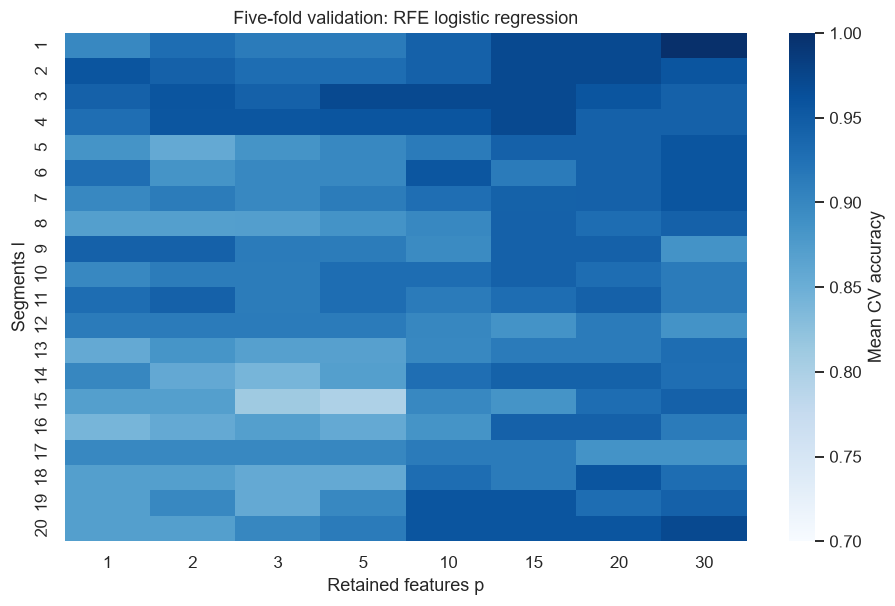

In [23]:
binary_cv = list(StratifiedGroupKFold(n_splits=5, shuffle=False)
                 .split(np.zeros((len(y_binary), 1)), y_binary, groups))
fold_rows = []
for fold, (fit_idx, valid_idx) in enumerate(binary_cv, 1):
    assert not set(groups[fit_idx]) & set(groups[valid_idx])
    assert len(np.unique(y_binary[fit_idx])) == len(np.unique(y_binary[valid_idx])) == 2
    fold_rows.append({'fold': fold, 'fit_n': len(fit_idx), 'validation_n': len(valid_idx),
                      'fit_bending': y_binary[fit_idx].sum(),
                      'validation_bending': y_binary[valid_idx].sum()})
display(pd.DataFrame(fold_rows))

def unpenalized_logistic():
    return LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000,
                              tol=1e-6, random_state=seed)

def rfe_pipeline(p=1):
    return Pipeline([('constant', VarianceThreshold()), ('scale', StandardScaler()),
                     ('rfe', RFE(unpenalized_logistic(), n_features_to_select=p,
                                 step=.2))])

def choose_best(results, simpler):
    maximum = results['cv_accuracy'].max()
    ties = results.loc[np.isclose(results['cv_accuracy'], maximum, rtol=0, atol=1e-12)]
    return ties.sort_values(simpler).iloc[0]

def run_search(factory, parameter_name, values, labels, folds):
    rows = []
    convergence_messages = 0
    for l in L_VALUES:
        search = GridSearchCV(factory(), {parameter_name: values}, cv=folds,
                              scoring='accuracy', refit=False, error_score='raise', n_jobs=1)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            search.fit(train_X[l], labels)
        convergence_messages += sum(issubclass(w.category, ConvergenceWarning) for w in caught)
        other = [str(w.message) for w in caught if not issubclass(w.category, ConvergenceWarning)]
        if other:
            print('Other warnings:', sorted(set(other)))
        for j, params in enumerate(search.cv_results_['params']):
            rows.append({'l': l, 'setting': params[parameter_name],
                         'cv_accuracy': search.cv_results_['mean_test_score'][j],
                         'cv_std': search.cv_results_['std_test_score'][j]})
    print(f'Convergence warnings across search fits: {convergence_messages}')
    return pd.DataFrame(rows), convergence_messages

rfe_results, rfe_warnings = run_search(rfe_pipeline, 'rfe__n_features_to_select',
                                      [1, 2, 3, 5, 10, 15, 20, 30], y_binary, binary_cv)
rfe_results = rfe_results.rename(columns={'setting': 'p'})
rfe_best = choose_best(rfe_results, ['p', 'l'])
rfe_l, rfe_p = int(rfe_best['l']), int(rfe_best['p'])
rfe_model = rfe_pipeline(rfe_p).fit(train_X[rfe_l], y_binary)
display(rfe_results.sort_values(['cv_accuracy', 'p', 'l'], ascending=[False, True, True]).head(15))
print(f'Selected (l, p) = ({rfe_l}, {rfe_p}); '
      f'mean CV accuracy = {rfe_best.cv_accuracy:.4f}, fold SD = {rfe_best.cv_std:.4f}')
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(rfe_results.pivot(index='l', columns='p', values='cv_accuracy'),
            vmin=.7, vmax=1, cmap='Blues', ax=ax, cbar_kws={'label': 'Mean CV accuracy'})
ax.set(title='Five-fold validation: RFE logistic regression', xlabel='Retained features p',
       ylabel='Segments l')
plt.show()

#### iv. Training confusion matrix, ROC, coefficients, and p-values

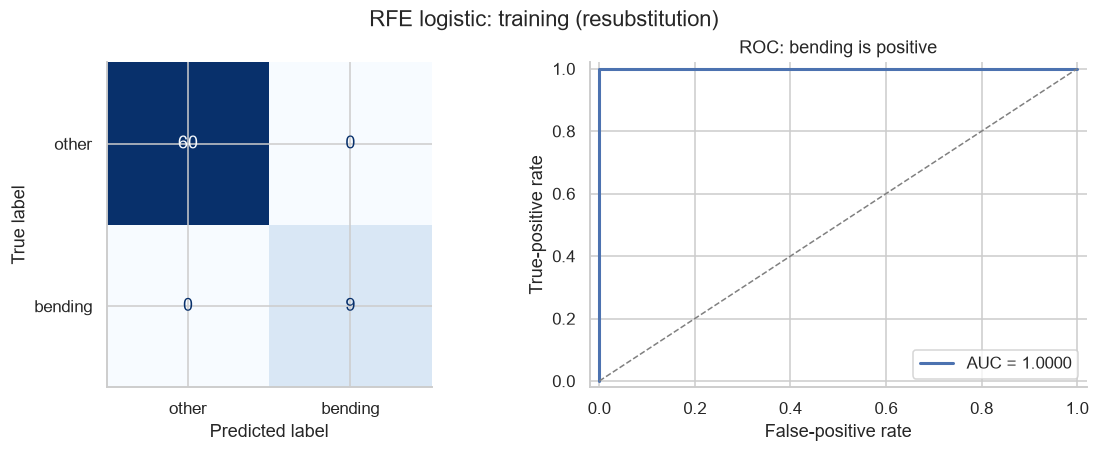

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
RFE logistic: training (resubstitution),1.0,1.0,1.0,1.0,1.0


,beta_standardized,beta_original_units,nominal_Wald_SE,nominal_Wald_p,usable_Wald_p
intercept,-16.5685,-8.2272,7867.4231,0.9983,NaN
min_s1_seg1,-2.9822,-0.3416,4796.8404,0.9995,NaN
max_s1_seg1,1.6052,0.3651,9428.3525,0.9999,NaN
mean_s1_seg1,-1.8380,-0.3765,34859.7201,1.0000,NaN
median_s1_seg1,-0.7550,-0.1534,12621.8513,1.0000,NaN
q3_s1_seg1,-3.9049,-0.8223,27906.4419,0.9999,NaN
max_s2_seg1,-1.8293,-0.3580,13274.1162,0.9999,NaN
median_s2_seg1,1.2228,0.8572,12902.6143,0.9999,NaN
std_s2_seg1,-0.7656,-0.8542,22757.7963,1.0000,NaN
min_s3_seg1,-0.8460,-0.2790,8687.0888,0.9999,NaN


Complete separation: True; information condition number: 2.13e+08; finite-fit Wald diagnostics usable: False


In [24]:
def binary_report(y, score, title):
    predicted = (np.asarray(score) >= 0).astype(int)
    metrics = {'accuracy': accuracy_score(y, predicted),
               'balanced_accuracy': balanced_accuracy_score(y, predicted),
               'bending_recall': recall_score(y, predicted, zero_division=0),
               'bending_precision': precision_score(y, predicted, zero_division=0),
               'auc': roc_auc_score(y, score)}
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    ConfusionMatrixDisplay(confusion_matrix(y, predicted, labels=[0, 1]),
                           display_labels=['other', 'bending']).plot(ax=axes[0], colorbar=False,
                                                                     cmap='Blues')
    fpr, tpr, _ = roc_curve(y, score)
    axes[1].plot(fpr, tpr, lw=2, label=f'AUC = {metrics["auc"]:.4f}')
    axes[1].plot([0, 1], [0, 1], '--', color='gray', lw=1)
    axes[1].set(xlabel='False-positive rate', ylabel='True-positive rate',
                xlim=(-.02, 1.02), ylim=(-.02, 1.02), title='ROC: bending is positive')
    axes[1].legend(loc='lower right')
    fig.suptitle(title)
    plt.show()
    display(pd.DataFrame([metrics], index=[title]))
    return metrics

rfe_train_score = rfe_model.decision_function(train_X[rfe_l])
rfe_train_metrics = binary_report(y_binary, rfe_train_score, 'RFE logistic: training (resubstitution)')

# Map RFE positions back through the constant-feature filter.
nonconstant_names = train_X[rfe_l].columns[rfe_model.named_steps['constant'].get_support()]
rfe_support = rfe_model.named_steps['rfe'].get_support()
retained_names = nonconstant_names[rfe_support]
Z = rfe_model.named_steps['scale'].transform(
    rfe_model.named_steps['constant'].transform(train_X[rfe_l]))[:, rfe_support]
fitted_logistic = rfe_model.named_steps['rfe'].estimator_
beta = np.r_[fitted_logistic.intercept_, fitted_logistic.coef_.ravel()]
D = np.column_stack([np.ones(len(Z)), Z])

# Complete separation is feasible iff all signed margins can be made >= 1.
signed_design = (2*y_binary - 1)[:, None] * D
separation_lp = linprog(np.zeros(D.shape[1]), A_ub=-signed_design,
                        b_ub=-np.ones(len(D)), bounds=[(None, None)]*D.shape[1], method='highs')
assert separation_lp.status in [0, 2], separation_lp.message
complete_separation = separation_lp.success
eta = D @ beta
weights = expit(eta) * expit(-eta)
information = D.T @ (weights[:, None] * D)
information_condition = np.linalg.cond(information)
if np.linalg.matrix_rank(information) == D.shape[1]:
    standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))
    nominal_p = 2 * norm.sf(np.abs(beta / standard_errors))
else:
    standard_errors = np.full(len(beta), np.nan)
    nominal_p = np.full(len(beta), np.nan)
inferentially_valid = (not complete_separation and information_condition < 1e10
                       and fitted_logistic.n_iter_[0] < fitted_logistic.max_iter)

scale = rfe_model.named_steps['scale'].scale_[rfe_support]
center = rfe_model.named_steps['scale'].mean_[rfe_support]
raw_slopes = beta[1:] / scale
raw_beta = np.r_[beta[0] - raw_slopes @ center, raw_slopes]
coefficient_table = pd.DataFrame({
    'beta_standardized': beta, 'beta_original_units': raw_beta,
    'nominal_Wald_SE': standard_errors, 'nominal_Wald_p': nominal_p,
    'usable_Wald_p': nominal_p if inferentially_valid else np.full(len(beta), np.nan)
}, index=['intercept', *retained_names])
display(coefficient_table)
print(f'Complete separation: {complete_separation}; information condition number: '
      f'{information_condition:.3g}; finite-fit Wald diagnostics usable: {inferentially_valid}')

The selected model uses $l=1$ and $p=30$. Its training accuracy and AUC
are both 1.0. The table shows the coefficients in standardized and original units.
The model is

$$\log\frac{p}{1-p}=\beta_0+\sum_j\beta_jz_j,$$

where $p$ is the probability of bending. I calculate the nominal Wald standard
errors from $(D^TWD)^{-1}$ and the p-values from
$2\Phi(-|\hat\beta_j/SE_j|)$.

There is a problem with interpreting these p-values: the selected features
completely separate the training classes. The unpenalized coefficients can
keep growing instead of reaching a finite maximum-likelihood estimate. The
values in the table are where the optimizer stopped, so I do not treat the
nominal p-values as valid significance tests. I mark `usable_Wald_p` as `NaN`
for this reason. Selecting features on the same data also affects the usual
interpretation of p-values.

#### v. Test the classifier using the selected segmentation

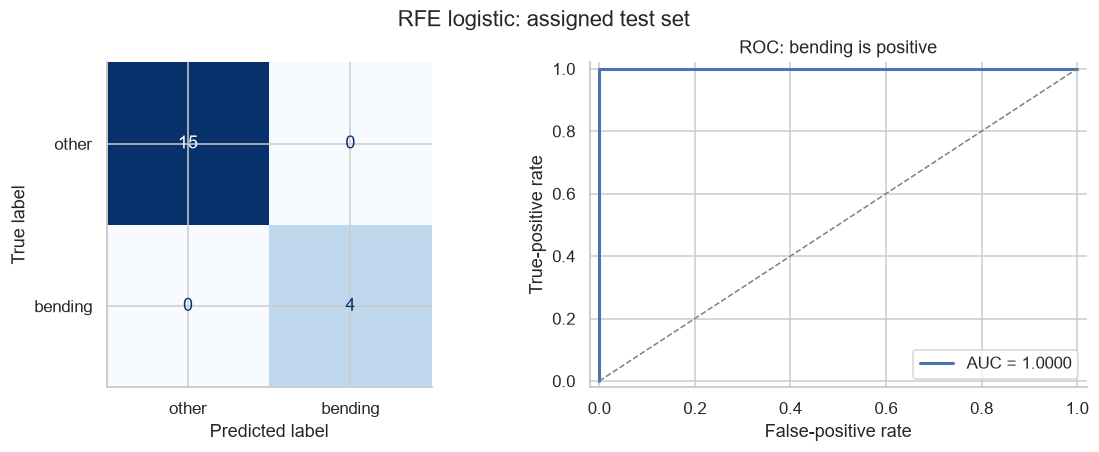

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
RFE logistic: assigned test set,1.0,1.0,1.0,1.0,1.0


,accuracy
Five-fold tuning CV,1.0
Training (resubstitution),1.0
Assigned test,1.0


In [25]:
# Use the same features and fitted transforms for the test set.
assert train_X[rfe_l].columns.equals(test_X[rfe_l].columns)
rfe_test_score = rfe_model.decision_function(test_X[rfe_l])
rfe_test_metrics = binary_report(y_binary_test, rfe_test_score, 'RFE logistic: assigned test set')
display(pd.DataFrame({'accuracy': [rfe_best.cv_accuracy, rfe_train_metrics['accuracy'],
                                   rfe_test_metrics['accuracy']]},
                     index=['Five-fold tuning CV', 'Training (resubstitution)', 'Assigned test']))

The model gets all 19 test recordings right, so its test accuracy is 100%,
the same as its CV accuracy. This is a small test set: one mistake would change
accuracy by about 5.26 percentage points.

#### vi. Class separation and coefficient instability

In [26]:
stability_rows = []
for tolerance in [1e-3, 1e-6, 1e-9]:
    model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=2000,
                               tol=tolerance, random_state=seed).fit(Z, y_binary)
    stability_rows.append({'tolerance': tolerance, 'iterations': model.n_iter_[0],
                            'coefficient_L2_norm': np.linalg.norm(model.coef_),
                            'training_accuracy': model.score(Z, y_binary),
                            'max_abs_log_odds': np.max(np.abs(model.decision_function(Z)))})
display(pd.DataFrame(stability_rows))

,tolerance,iterations,coefficient_L2_norm,training_accuracy,max_abs_log_odds
0,1.0000e-03,10,5.4774,1.0,24.2359
1,1.0000e-06,20,13.0826,1.0,56.6422
2,1.0000e-09,31,21.4077,1.0,90.2687


Yes. The selected features completely separate the classes. When I tighten
the optimizer tolerance, the coefficient norm grows from about 5.48 to 21.41,
but training accuracy stays at 100%. So getting perfect predictions does not
mean the coefficient estimates are stable.

#### vii. Imbalance and case-control sampling

The classes are imbalanced: training has 60 other recordings and 9 bending
recordings, while testing has 15 other and 4 bending recordings. Always
predicting the majority class would already give $60/69=86.96\%$ training accuracy.

For case-control sampling, I keep all 9 bending recordings and randomly choose
9 other recordings without replacement. I refit the model with the same selected
features. Since the sampled class proportions differ from the original data,
I adjust the intercept:

$$\beta_{0,\mathrm{corrected}}=\beta_{0,\mathrm{sample}}
+\log\frac{\pi}{1-\pi}-\log\frac{\pi_s}{1-\pi_s}.$$

Here $\pi=9/69$ and $\pi_s=1/2$, so the adjustment is
$\log(9/60)\approx-1.8971$. This correction changes only the intercept.
It can change predictions at the 0.5 threshold, but not the ranking of scores,
so the ROC curve and AUC stay the same.

,case_control
sample_intercept,-7.2840
intercept_adjustment,-1.8971
corrected_intercept,-9.1811
sample_cases,9.0000
sample_controls,9.0000


,unchanged_slopes
min_s1_seg1,-3.2865
max_s1_seg1,0.4471
mean_s1_seg1,-0.6156
median_s1_seg1,0.3893
q3_s1_seg1,-1.1429
max_s2_seg1,-0.3327
median_s2_seg1,-0.3341
std_s2_seg1,-0.5792
min_s3_seg1,0.1068
max_s3_seg1,2.0018


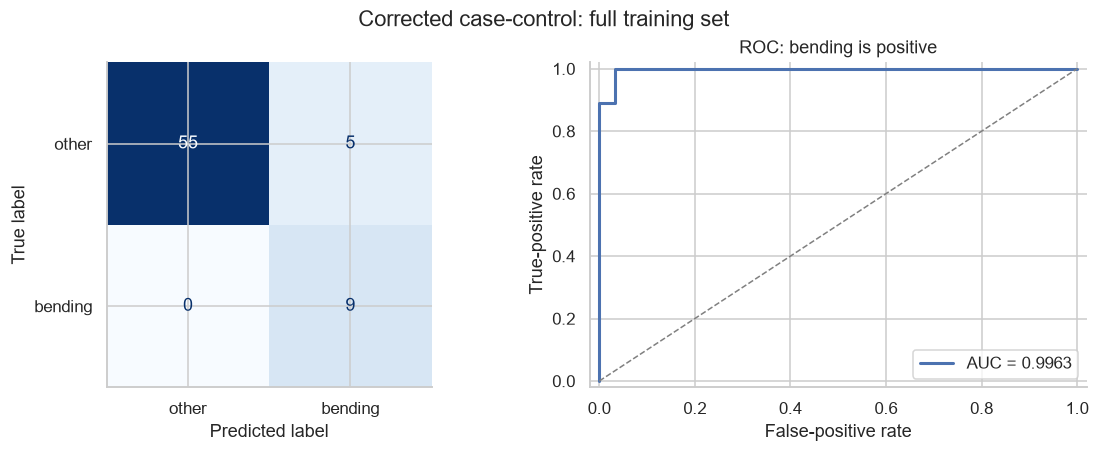

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
Corrected case-control: full training set,0.9275,0.9583,1.0,0.6429,0.9963


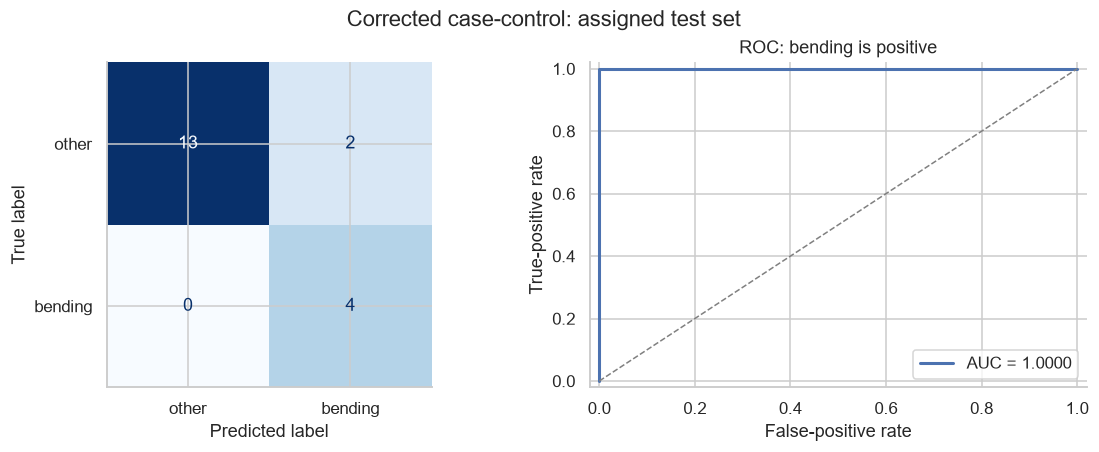

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
Corrected case-control: assigned test set,0.8947,0.9333,1.0,0.6667,1.0


,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
Original RFE logistic,1.0000,1.0000,1.0,1.0000,1.0
Corrected case-control,0.8947,0.9333,1.0,0.6667,1.0


In [27]:
rng = np.random.default_rng(seed)
case_idx = np.flatnonzero(y_binary == 1)
control_idx = rng.choice(np.flatnonzero(y_binary == 0), size=len(case_idx), replace=False)
sample_idx = np.sort(np.r_[case_idx, control_idx])
case_control = unpenalized_logistic().fit(Z[sample_idx], y_binary[sample_idx])
sample_prevalence = y_binary[sample_idx].mean()
target_prevalence = y_binary.mean()
intercept_adjustment = logit(target_prevalence) - logit(sample_prevalence)
Z_test = rfe_model.named_steps['scale'].transform(
    rfe_model.named_steps['constant'].transform(test_X[rfe_l]))[:, rfe_support]
cc_train_raw = case_control.decision_function(Z)
cc_test_raw = case_control.decision_function(Z_test)
cc_train_score = cc_train_raw + intercept_adjustment
cc_test_score = cc_test_raw + intercept_adjustment
display(pd.Series({'sample_intercept': case_control.intercept_[0],
                   'intercept_adjustment': intercept_adjustment,
                   'corrected_intercept': case_control.intercept_[0] + intercept_adjustment,
                   'sample_cases': len(case_idx), 'sample_controls': len(control_idx)},
                  name='case_control').to_frame())
display(pd.Series(case_control.coef_.ravel(), index=retained_names, name='unchanged_slopes').to_frame())
cc_train_metrics = binary_report(y_binary, cc_train_score, 'Corrected case-control: full training set')
cc_test_metrics = binary_report(y_binary_test, cc_test_score, 'Corrected case-control: assigned test set')
assert np.isclose(roc_auc_score(y_binary_test, cc_test_raw), cc_test_metrics['auc'])
display(pd.DataFrame([rfe_test_metrics, cc_test_metrics],
                     index=['Original RFE logistic', 'Corrected case-control']))

The corrected case-control model gets 17 of 19 test recordings right,
compared with 19 of 19 for the original model. Both find all four bending
recordings, but the sampled model makes two false positive predictions.
Sampling did not improve the result here.

One limitation is that I fit 30 features and an intercept using only 18 sampled
recordings. There is not enough information to estimate all coefficients uniquely.
The classes are also separated, so the probabilities should be treated carefully.
Using fewer features or regularization would make the fit more stable.

### (b) Binary Classification Using L1-penalized Logistic Regression

#### i. Cross-validating both segmentation and regularization

For L1 logistic regression, I try $l=1,\ldots,20$ and
$C\in\{0.01,0.03,0.1,0.3,1,3,10,30,100\}$ with the same five CV folds.
A smaller $C$ means a stronger penalty. I standardize within each fold and
use `liblinear`. L1 does feature selection by setting some coefficients to zero.
For ties, I choose the smaller $C$, then the smaller $l$.

Convergence warnings across search fits: 0


,l,C,cv_accuracy,cv_std
0,1,0.3,0.9714,0.0571
1,2,100.0,0.9714,0.0350
2,3,0.3,0.9714,0.0350
3,4,1.0,0.9571,0.0571
4,5,1.0,0.9286,0.0452
5,6,3.0,0.9429,0.0286
6,7,1.0,0.9429,0.0535
7,8,100.0,0.9429,0.0535
8,9,1.0,0.9418,0.0538
9,10,100.0,0.9286,0.0639


Selected l=1, C=0.3; CV accuracy=0.9714
Nonzero slopes: 3 of 42 input features


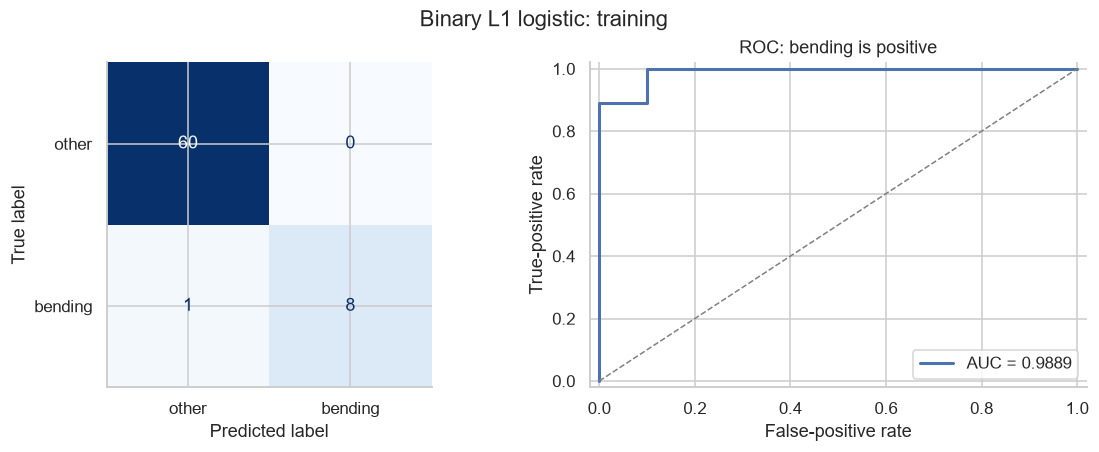

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
Binary L1 logistic: training,0.9855,0.9444,0.8889,1.0,0.9889


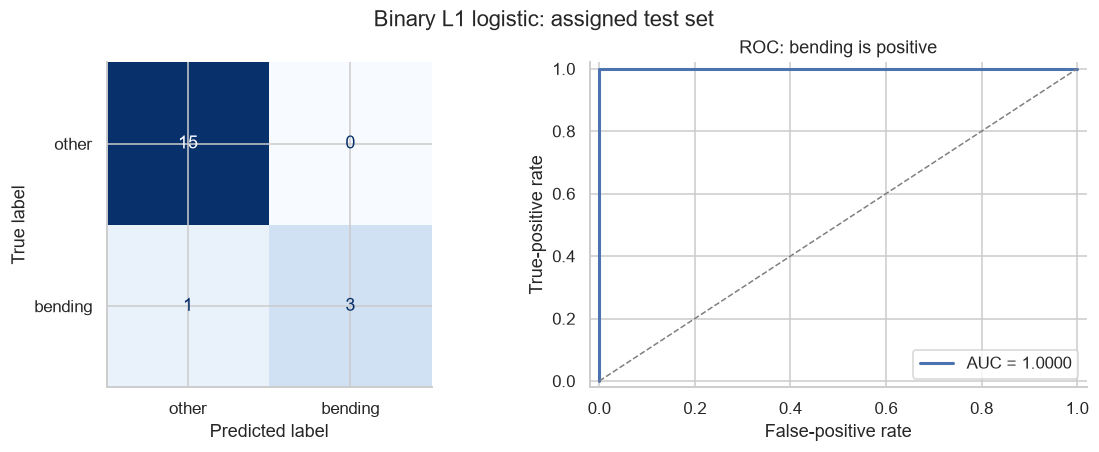

,accuracy,balanced_accuracy,bending_recall,bending_precision,auc
Binary L1 logistic: assigned test set,0.9474,0.875,0.75,1.0,1.0


In [28]:
C_VALUES = [.01, .03, .1, .3, 1., 3., 10., 30., 100.]
def binary_l1_pipeline():
    return Pipeline([('constant', VarianceThreshold()), ('scale', StandardScaler()),
                     ('model', LogisticRegression(penalty='l1', solver='liblinear',
                                                   max_iter=5000, tol=1e-6,
                                                   random_state=seed))])

l1_results, l1_warnings = run_search(binary_l1_pipeline, 'model__C', C_VALUES,
                                    y_binary, binary_cv)
l1_results = l1_results.rename(columns={'setting': 'C'})
l1_best = choose_best(l1_results, ['C', 'l'])
l1_l = int(l1_best['l'])
l1_model = binary_l1_pipeline().set_params(model__C=float(l1_best['C'])).fit(train_X[l1_l], y_binary)
display(l1_results.loc[l1_results.groupby('l')['cv_accuracy'].idxmax()].reset_index(drop=True))
print(f'Selected l={l1_l}, C={l1_best["C"]:g}; CV accuracy={l1_best.cv_accuracy:.4f}')
l1_nonzero = np.count_nonzero(l1_model.named_steps['model'].coef_)
print(f'Nonzero slopes: {l1_nonzero} of {42*l1_l} input features')
l1_train_metrics = binary_report(y_binary, l1_model.decision_function(train_X[l1_l]),
                                  'Binary L1 logistic: training')
l1_test_metrics = binary_report(y_binary_test, l1_model.decision_function(test_X[l1_l]),
                                 'Binary L1 logistic: assigned test set')

#### ii. Comparison with variable selection

In [29]:
binary_comparison = pd.DataFrame([
    {'method': 'Unpenalized logistic + RFE', 'l': rfe_l, 'retained_features': rfe_p,
     'cv_accuracy': rfe_best.cv_accuracy, 'cv_fold_sd': rfe_best.cv_std,
     'test_accuracy': rfe_test_metrics['accuracy'], 'test_auc': rfe_test_metrics['auc']},
    {'method': 'L1 logistic', 'l': l1_l, 'retained_features': l1_nonzero,
     'cv_accuracy': l1_best.cv_accuracy, 'cv_fold_sd': l1_best.cv_std,
     'test_accuracy': l1_test_metrics['accuracy'], 'test_auc': l1_test_metrics['auc']}
]).set_index('method')
display(binary_comparison)

,l,retained_features,cv_accuracy,cv_fold_sd,test_accuracy,test_auc
method,,,,,,
Unpenalized logistic + RFE,1,30,1.0000,0.0000,1.0000,1.0
L1 logistic,1,3,0.9714,0.0571,0.9474,1.0


RFE does better in this run. It gets 100% CV and test accuracy, while L1 gets
97.14% CV accuracy and 94.74% test accuracy. The selected L1 model has $l=1$
and $C=0.3$. It keeps only 3 features, compared with 30 for RFE, and the test
accuracy difference is just one recording.

I find L1 easier to implement because it fits the model and selects features
in the same step. RFE requires repeated fits, and p-value selection would also
need reliable standard errors. I used the allowed RFE alternative in part (a),
so the measured performance comparison here is L1 versus RFE. The separation
problem makes ordinary p-value pruning unreliable for this data.

### (c) Multi-class Classification (The Realistic Case)

#### i. L1-penalized multinomial logistic regression

Here I keep all seven activity labels and use `saga` for L1-penalized
multinomial logistic regression. I try $l=1,\ldots,20$ and
$C\in\{0.01,0.1,1,10\}$. For ties, I choose smaller $C$, then smaller $l$.

I use the same five grouped, stratified folds for all three multiclass methods.
There are only four bending2 recordings in training, so one validation fold
has no bending2 examples. All fitting folds still contain every class.
I use accuracy for CV and calculate the test AUC using the test set,
which contains all seven classes.

In [30]:
with warnings.catch_warnings(record=True) as fold_warnings:
    warnings.simplefilter('always', UserWarning)
    multi_cv = list(StratifiedGroupKFold(n_splits=5, shuffle=False)
                    .split(np.zeros((len(y_multi), 1)), y_multi, groups))
for warning in fold_warnings:
    print('Fold construction:', warning.message)
multi_fold_counts = []
for fold, (fit_idx, valid_idx) in enumerate(multi_cv, 1):
    assert set(y_multi[fit_idx]) == set(activities)
    assert not set(groups[fit_idx]) & set(groups[valid_idx])
    multi_fold_counts.append(pd.Series(y_multi[valid_idx]).value_counts()
                             .reindex(activities, fill_value=0).rename(f'fold {fold}'))
display(pd.DataFrame(multi_fold_counts))

def multi_l1_pipeline():
    return Pipeline([('constant', VarianceThreshold()), ('scale', StandardScaler()),
                     ('model', LogisticRegression(penalty='l1', solver='saga',
                                                   max_iter=10000, tol=1e-3,
                                                   random_state=seed))])

multi_results, multi_warnings = run_search(multi_l1_pipeline, 'model__C', [.01, .1, 1., 10.],
                                          y_multi, multi_cv)
multi_results = multi_results.rename(columns={'setting': 'C'})
multi_best = choose_best(multi_results, ['C', 'l'])
multi_l = int(multi_best['l'])
multi_model = multi_l1_pipeline().set_params(model__C=float(multi_best['C'])).fit(
    train_X[multi_l], y_multi)
display(multi_results.loc[multi_results.groupby('l')['cv_accuracy'].idxmax()].reset_index(drop=True))
print(f'Selected l={multi_l}, C={multi_best["C"]:g}; CV accuracy={multi_best.cv_accuracy:.4f}')
print('Final SAGA iterations:', multi_model.named_steps['model'].n_iter_)
print('Nonzero class-specific slopes:', np.count_nonzero(multi_model.named_steps['model'].coef_))

Fold construction: The least populated class in y has only 4 members, which is less than n_splits=5.


,bending1,bending2,cycling,lying,sitting,standing,walking
fold 1,1,1,2,3,2,2,3
fold 2,1,0,2,3,3,3,2
fold 3,1,1,2,2,3,3,2
fold 4,1,1,3,2,2,2,3
fold 5,1,1,3,2,2,2,2


Convergence warnings across search fits: 0


,l,C,cv_accuracy,cv_std
0,1,10.0,0.9132,0.0698
1,2,10.0,0.8681,0.0869
2,3,10.0,0.8253,0.0876
3,4,10.0,0.8549,0.0640
4,5,10.0,0.8396,0.0729
5,6,10.0,0.8253,0.0876
6,7,10.0,0.8253,0.0876
7,8,10.0,0.8110,0.0981
8,9,1.0,0.8396,0.0858
9,10,1.0,0.8110,0.0744


Selected l=1, C=10; CV accuracy=0.9132
Final SAGA iterations: [341]
Nonzero class-specific slopes: 132


For the multiclass confusion matrix, rows are the true activities and columns
are the predicted activities. For each ROC curve, I treat one activity as the
positive class and combine the other six as the negative class.
Macro AUC is the average of the seven class AUCs. Micro AUC pools all the
class indicators and predicted probabilities before calculating one AUC.
I followed the [scikit-learn multiclass ROC example](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_roc.html).

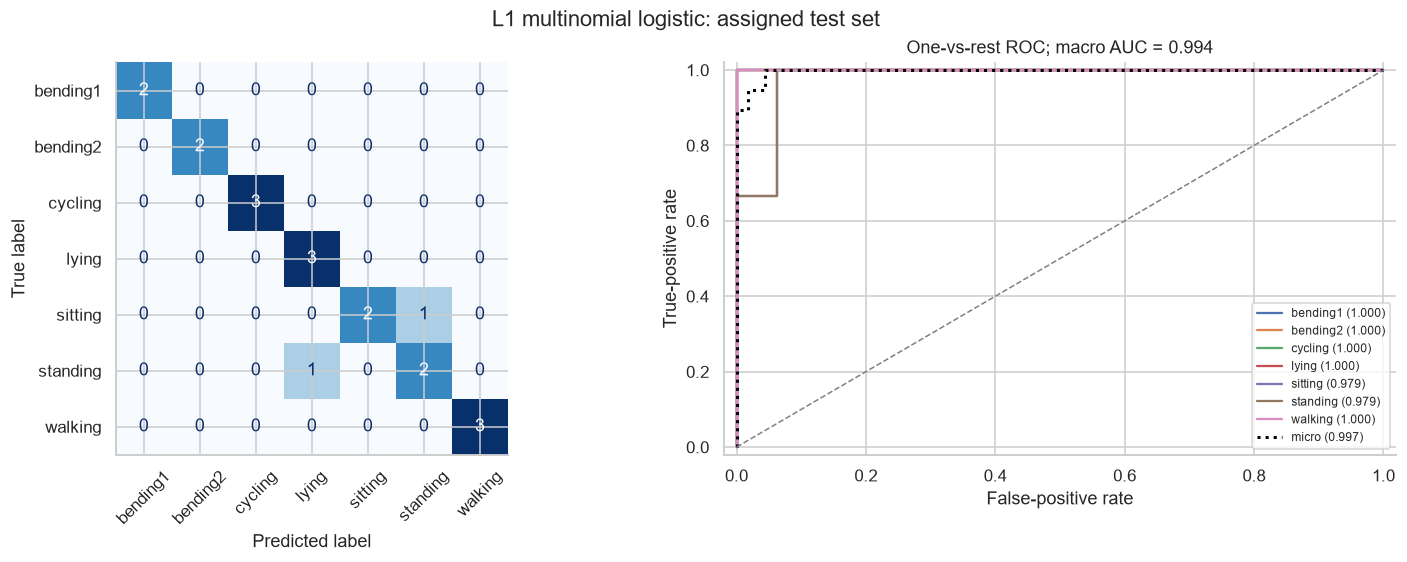

,accuracy,test_error,macro_f1,macro_auc_ovr,micro_auc_ovr
L1 multinomial logistic: assigned test set,0.8947,0.1053,0.9034,0.994,0.9968


In [31]:
def multiclass_report(model, X, y, title):
    probabilities = model.predict_proba(X)
    classes = model.classes_
    assert list(classes) == activities
    assert np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1., atol=1e-8)
    predicted = model.predict(X)
    truth = label_binarize(y, classes=classes)
    per_class_auc = [roc_auc_score(truth[:, j], probabilities[:, j]) for j in range(len(classes))]
    metrics = {'accuracy': accuracy_score(y, predicted),
               'test_error': 1-accuracy_score(y, predicted),
               'macro_f1': f1_score(y, predicted, average='macro', zero_division=0),
               'macro_auc_ovr': np.mean(per_class_auc),
               'micro_auc_ovr': roc_auc_score(truth.ravel(), probabilities.ravel())}
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
    ConfusionMatrixDisplay(confusion_matrix(y, predicted, labels=classes), display_labels=classes).plot(
        ax=axes[0], colorbar=False, cmap='Blues', xticks_rotation=45)
    for j, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(truth[:, j], probabilities[:, j])
        axes[1].plot(fpr, tpr, label=f'{label} ({per_class_auc[j]:.3f})')
    micro_fpr, micro_tpr, _ = roc_curve(truth.ravel(), probabilities.ravel())
    axes[1].plot(micro_fpr, micro_tpr, ':', color='black', lw=2,
                 label=f'micro ({metrics["micro_auc_ovr"]:.3f})')
    axes[1].plot([0, 1], [0, 1], '--', color='gray', lw=1)
    axes[1].set(xlabel='False-positive rate', ylabel='True-positive rate',
                title=f'One-vs-rest ROC; macro AUC = {metrics["macro_auc_ovr"]:.3f}',
                xlim=(-.02, 1.02), ylim=(-.02, 1.02))
    axes[1].legend(loc='lower right', fontsize=8)
    fig.suptitle(title)
    plt.show()
    display(pd.DataFrame([metrics], index=[title]))
    return metrics

multi_metrics = multiclass_report(multi_model, test_X[multi_l], y_multi_test,
                                   'L1 multinomial logistic: assigned test set')

#### ii. Gaussian and multinomial naive Bayes

I compare Gaussian and multinomial naive Bayes. Gaussian NB models each
feature with a normal distribution within a class. Multinomial NB uses
nonnegative feature values and additive smoothing. Both estimate the class
prior probabilities from the training data.

For Gaussian NB, I tune $l$ and `var_smoothing` in
$\{10^{-9},10^{-7},10^{-5},10^{-3}\}$. For multinomial NB, I tune $l$ and
`alpha` in $\{0.01,0.1,1,10\}$. I keep the features in their original units
because centering would create negative values, which multinomial NB cannot use.
These summary statistics are not counts, and some are correlated, so the NB
assumptions are not an exact match for this data.
Reference: [scikit-learn naive Bayes documentation](https://scikit-learn.org/1.7/modules/naive_bayes.html).

Convergence warnings across search fits: 0
Convergence warnings across search fits: 0


,l,var_smoothing,cv_accuracy,cv_std
0,1,1.0000e-07,0.8571,0.1010
1,2,1.0000e-03,0.7967,0.0955
2,3,1.0000e-03,0.8121,0.0960
3,4,1.0000e-03,0.8407,0.0830
4,5,1.0000e-03,0.8396,0.1246
5,6,1.0000e-03,0.7978,0.1219
6,7,1.0000e-03,0.7978,0.0935
7,8,1.0000e-03,0.8407,0.1227
8,9,1.0000e-03,0.8121,0.1239
9,10,1.0000e-03,0.7967,0.1315


,l,alpha,cv_accuracy,cv_std
0,1,1.00,0.8418,0.0822
1,2,1.00,0.7989,0.1131
2,3,0.01,0.7989,0.1299
3,4,1.00,0.8000,0.1229
4,5,1.00,0.8418,0.0687
5,6,1.00,0.8418,0.0687
6,7,1.00,0.8121,0.0717
7,8,0.01,0.8132,0.0711
8,9,0.01,0.7978,0.1219
9,10,0.10,0.8264,0.0562


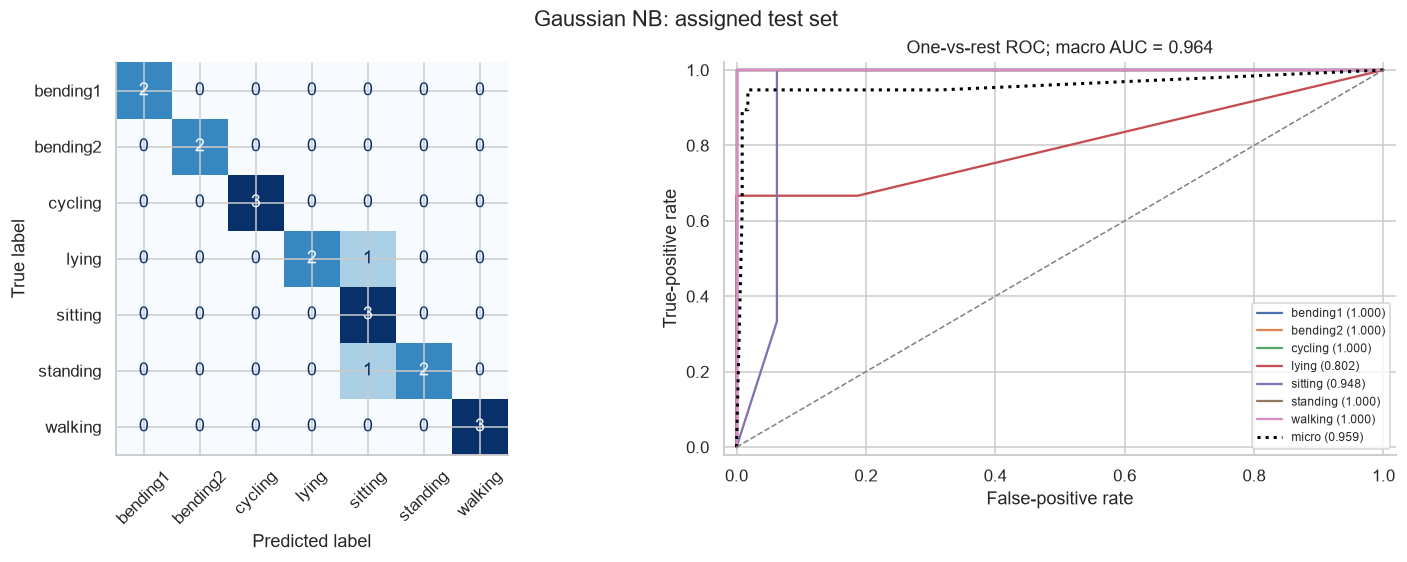

,accuracy,test_error,macro_f1,macro_auc_ovr,micro_auc_ovr
Gaussian NB: assigned test set,0.8947,0.1053,0.9071,0.9643,0.9594


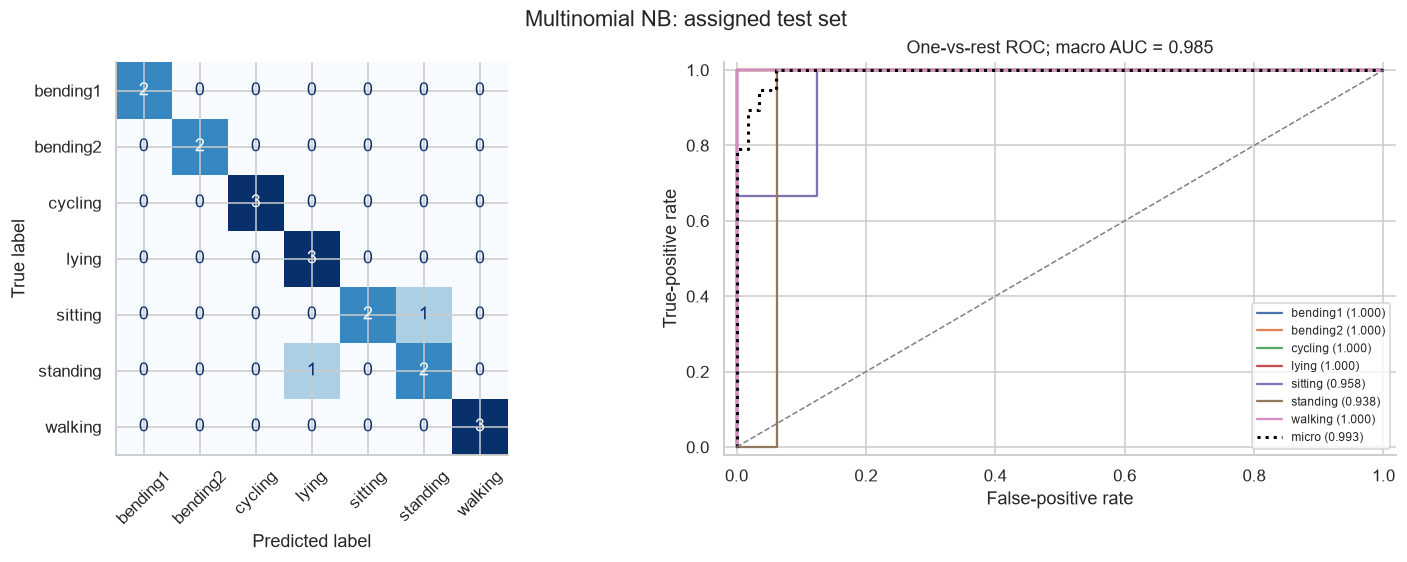

,accuracy,test_error,macro_f1,macro_auc_ovr,micro_auc_ovr
Multinomial NB: assigned test set,0.8947,0.1053,0.9034,0.9851,0.9931


In [32]:
def gaussian_pipeline():
    return Pipeline([('constant', VarianceThreshold()), ('model', GaussianNB())])

def multinomial_nb_pipeline():
    return Pipeline([('constant', VarianceThreshold()), ('model', MultinomialNB())])

assert all((frame.to_numpy() >= 0).all() for frame in segment_data.values())
gnb_results, _ = run_search(gaussian_pipeline, 'model__var_smoothing',
                            [1e-9, 1e-7, 1e-5, 1e-3], y_multi, multi_cv)
gnb_results = gnb_results.rename(columns={'setting': 'var_smoothing'})
gnb_best = choose_best(gnb_results, ['l', 'var_smoothing'])
gnb_l = int(gnb_best['l'])
gnb_model = gaussian_pipeline().set_params(model__var_smoothing=float(gnb_best['var_smoothing'])).fit(
    train_X[gnb_l], y_multi)

mnb_results, _ = run_search(multinomial_nb_pipeline, 'model__alpha',
                            [.01, .1, 1., 10.], y_multi, multi_cv)
mnb_results = mnb_results.rename(columns={'setting': 'alpha'})
mnb_best = choose_best(mnb_results, ['l', 'alpha'])
mnb_l = int(mnb_best['l'])
mnb_model = multinomial_nb_pipeline().set_params(model__alpha=float(mnb_best['alpha'])).fit(
    train_X[mnb_l], y_multi)
display(gnb_results.loc[gnb_results.groupby('l')['cv_accuracy'].idxmax()].reset_index(drop=True))
display(mnb_results.loc[mnb_results.groupby('l')['cv_accuracy'].idxmax()].reset_index(drop=True))
gnb_metrics = multiclass_report(gnb_model, test_X[gnb_l], y_multi_test, 'Gaussian NB: assigned test set')
mnb_metrics = multiclass_report(mnb_model, test_X[mnb_l], y_multi_test, 'Multinomial NB: assigned test set')

#### iii. Comparison

,l,cv_accuracy,cv_fold_sd,accuracy,test_error,macro_f1,macro_auc_ovr,micro_auc_ovr
method,,,,,,,,
L1 multinomial logistic,1,0.9132,0.0698,0.8947,0.1053,0.9034,0.9940,0.9968
Gaussian NB,1,0.8571,0.1010,0.8947,0.1053,0.9071,0.9643,0.9594
Multinomial NB,1,0.8418,0.0822,0.8947,0.1053,0.9034,0.9851,0.9931


Test recordings without an exact training duplicate: 16 of 19


,assigned_test_n,assigned_accuracy,nonduplicate_test_n,nonduplicate_accuracy
method,,,,
L1 multinomial logistic,19,0.8947,16,0.875
Gaussian NB,19,0.8947,16,0.875
Multinomial NB,19,0.8947,16,0.875


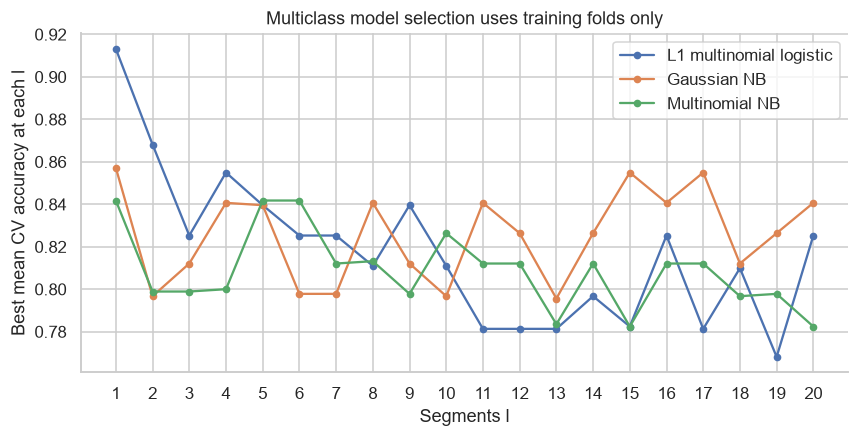

In [33]:
multiclass_models = {
    'L1 multinomial logistic': (multi_model, multi_l, multi_best, multi_metrics),
    'Gaussian NB': (gnb_model, gnb_l, gnb_best, gnb_metrics),
    'Multinomial NB': (mnb_model, mnb_l, mnb_best, mnb_metrics)
}
multiclass_comparison = pd.DataFrame([
    {'method': name, 'l': l, 'cv_accuracy': best.cv_accuracy, 'cv_fold_sd': best.cv_std, **metrics}
    for name, (_, l, best, metrics) in multiclass_models.items()
]).set_index('method').sort_values('cv_accuracy', ascending=False)
display(multiclass_comparison)

# Also check accuracy after excluding test recordings duplicated in training.
novel_test = ~metadata.loc[test_ids, 'sha256'].isin(metadata.loc[train_ids, 'sha256']).to_numpy()
print(f'Test recordings without an exact training duplicate: {novel_test.sum()} of 19')
novel_comparison = pd.DataFrame([
    {'method': name, 'assigned_test_n': 19, 'assigned_accuracy': metrics['accuracy'],
     'nonduplicate_test_n': novel_test.sum(),
     'nonduplicate_accuracy': accuracy_score(y_multi_test[novel_test],
                                             model.predict(test_X[l])[novel_test])}
    for name, (model, l, best, metrics) in multiclass_models.items()
]).set_index('method')
display(novel_comparison)

fig, ax = plt.subplots(figsize=(9, 4))
for name, results in [('L1 multinomial logistic', multi_results),
                       ('Gaussian NB', gnb_results), ('Multinomial NB', mnb_results)]:
    curve = results.groupby('l')['cv_accuracy'].max()
    ax.plot(curve.index, curve, marker='o', ms=4, label=name)
ax.set(xlabel='Segments l', ylabel='Best mean CV accuracy at each l', xticks=list(range(1, 21)),
       title='Multiclass model selection uses training folds only')
ax.legend()
plt.show()

All three methods choose $l=1$. L1 multinomial logistic regression has the
highest CV accuracy at 91.32%, with $C=10$. Gaussian NB gets 85.71%
(`var_smoothing=1e-7`), and multinomial NB gets 84.18% (`alpha=1`).
All three get 17 of 19 test recordings right: 89.47% accuracy, or 10.53% test error.
I would choose L1 multinomial logistic regression because of its better CV result,
although the test accuracies are tied.

As another check, I remove the three test recordings that duplicate training
recordings. Each model then gets 14 of 16 right (87.5%). I only use this as a
check after fitting, not to choose the models. The test set is small and all
recordings are from the same person, so I would not assume the same accuracy
for new people.

## 3. ISLR 4.8.3 - Why the QDA decision rule is quadratic

Reference: James, Witten, Hastie, and Tibshirani,
[*An Introduction to Statistical Learning*, second edition](https://hastie.su.domains/ISLR2/ISLRv2_corrected_June_2023.pdf.download.html),
Section 4.8, Exercise 3 (p. 189).

Let $\pi_k=P(Y=k)$ and $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$.
By Bayes' theorem,

$$P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_j\pi_j f_j(x)}.$$

The denominator is the same for every class, so I only need to compare
$\pi_k f_k(x)$. Taking the log of the normal density and dropping the common
constant $-\frac12\log(2\pi)$ gives

$$\delta_k(x)=\log\pi_k-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the square,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
+\log\pi_k-\frac12\log\sigma_k^2-\frac{\mu_k^2}{2\sigma_k^2}.$$

This has the form $a_kx^2+b_kx+c_k$. The boundary between two classes is
where their scores are equal. If their variances differ, the $x^2$ terms do
not cancel, so the boundary equation is quadratic. If the variances are equal,
they do cancel, giving the linear rule used by LDA.

## 4. ISLR 4.8.7 - Posterior probability of a dividend

Reference: ISLR, second edition, Section 4.8, Exercise 7 (p. 191).

Let $D$ mean that the company pays a dividend. We are given
$P(D)=0.8$, $P(D^c)=0.2$, means 10 and 0, and variance 36 for both groups.
Using Bayes' theorem at $X=4$,

$$P(D\mid X=4)=\frac{0.8\,f(4;10,36)}
{0.8\,f(4;10,36)+0.2\,f(4;0,36)}.$$

The normal density constants cancel, so

$$P(D\mid X=4)=\frac{0.8\,e^{-(4-10)^2/(2\cdot36)}}
{0.8\,e^{-(4-10)^2/(2\cdot36)}+0.2\,e^{-(4-0)^2/(2\cdot36)}}
=\frac{1}{1+0.25e^{5/18}}\approx0.751852.$$

The probability is about **75.19%**, so I would predict that the company
pays a dividend. Even though a profit of 4 is closer to the no-dividend mean,
the higher prior probability of paying a dividend outweighs that here.

In [34]:
dividend_probability = (.8*norm.pdf(4, loc=10, scale=6) /
                        (.8*norm.pdf(4, loc=10, scale=6) + .2*norm.pdf(4, loc=0, scale=6)))
print(f'P(dividend | profit = 4) = {dividend_probability:.6f} ({dividend_probability:.2%})')

P(dividend | profit = 4) = 0.751852 (75.19%)
